---
### Final version of HPK angular fits (hopefully) - V5


1. plot the relative PDE vs angle
2. divide out the optics for known thickness, wlen
3. divide out the complete PDE for known thickness, wlen, PN paramters from other fits
4. look at this 'factored' out FF(theta) (for Vis and UV)
    * compare it with the shadowed FF

5. try fitting the FF(theta) with the shadowing + reflected function?



---

------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


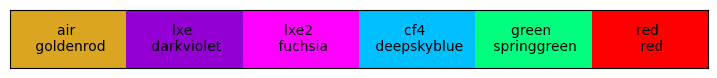

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec


from scipy import optimize as opt
import iminuit
from iminuit import Minuit

import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PDEModel import PNJunction as PNJ

import FittingTools.FittingFunctions as SS
from FittingTools.FittingFunctions import *
from FittingTools.HPK_angularTools import *


MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

---
### Geometry of FF --> ff, W, H
(see main_Angular_PlotTools.ipynb) for the relative and/or absolute ff, W solution

__Relative:__
$$ FF(\theta) = [4W^2 - 4W + 1] - (1-2W)H\tan\theta $$
$$ 0 = W^2 - W + \frac{1-FF}{4} $$
$$ \mathbf{a}x^2 + \mathbf{b}x + \mathbf{c} = 0$$
$$a = 1, b = -1, c = \frac{1-FF}{4}$$

__Absolute:__  
$$ ff^2 \mathbf{-p} ff + \mathbf{(1-FF)p^2/4} = 0 $$
$$a = 1, b = -p, c = \frac{(1-FF)p^2}{4}$$

In [29]:

FF = 0.6
pp = 50 # units of um
# FF2 = 0.7
# pp2 = 75 # units of um

## Absolute
case50 = SS.quadraticSolution(a = 1, b = -pp, c = (1-FF)*(pp**2)/4)
print("50um ppitch, ff: ", case50)
print("consistency test (zero):", FF - SS.FF_theta_absolute(theta=0, ff=case50[1], h = 0, p = pp))
print(f"ff size: {case50[1]:0.2f} um")

# relative
print("\n----- relative -----")
case50_relative = SS.quadraticSolution(a = 1, b = -1, c = (1-FF)/4)
print("50um ppitch relative, W = ff/p: ", case50_relative)
print("consistency test (zero):", FF - SS.FF_theta_relative(theta=0, W=case50_relative[1], H = 0))
print(f"ff size: {case50_relative[1]*pp:0.2f} um")


W50 = min(case50_relative)
# H50 = 2./pp # 2.5um from AFM measurements


50um ppitch, ff:  (44.364916731037084, 5.635083268962916)
consistency test (zero): 0.0
ff size: 5.64 um

----- relative -----
50um ppitch relative, W = ff/p:  (0.8872983346207417, 0.1127016653792583)
consistency test (zero): -1.1102230246251565e-16
ff size: 5.64 um


---
## Visible Data - March 2024 - many .csv's

This is warm!

In [30]:
dataPath = os.path.join(VERA_DATA_PATH, "HPK_angularScans_March2024")

filelist_6V = get_csv_files_with_identifier(dataPath, "6oV")
sorted_f6V_list = sorted(filelist_6V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))
vis6V = [] # reset as empty below to avoid double filling

filelist_1V = get_csv_files_with_identifier(dataPath, "1oV")
sorted_f1V_list = sorted(filelist_1V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))
vis1V = []

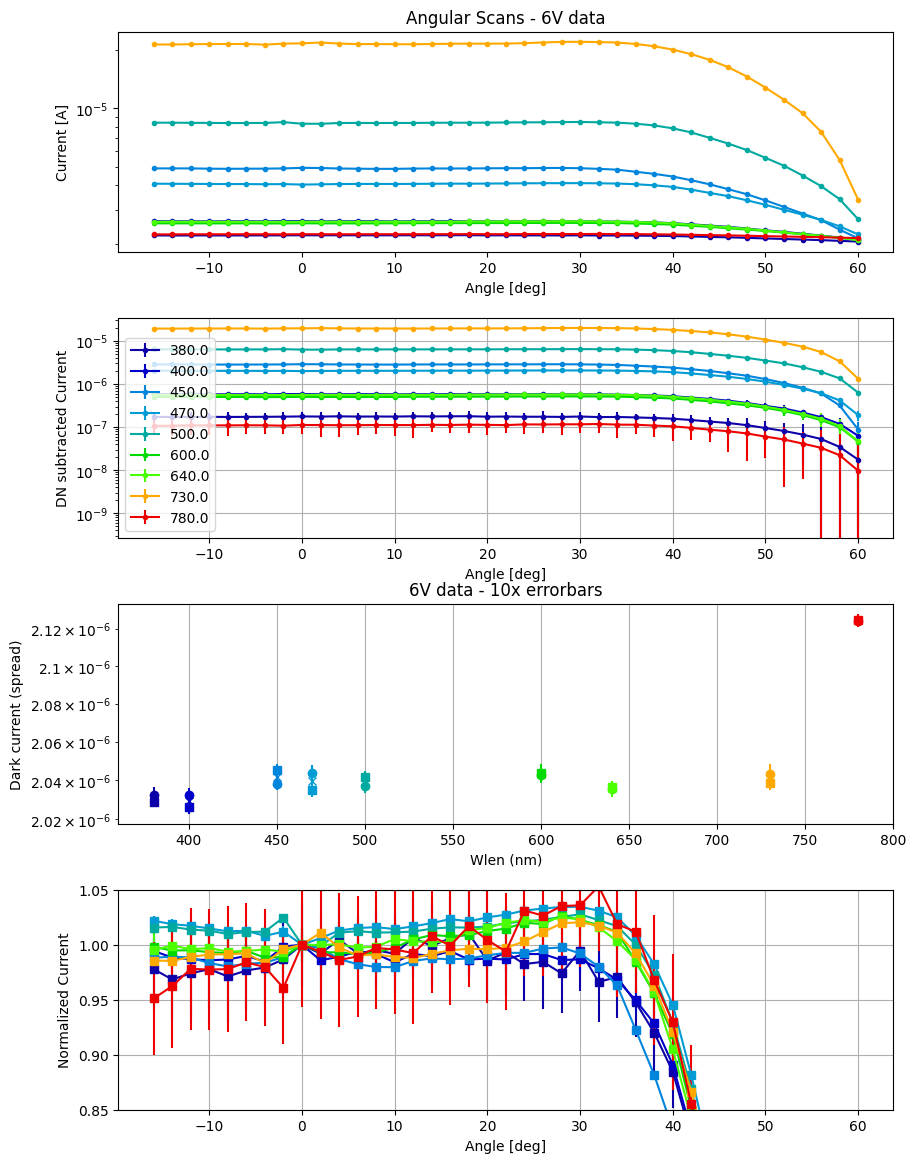

In [31]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, sharex=False, figsize = (10, 14))

skip6V = ["830"]
vis6V = []
for i, file in enumerate(sorted_f6V_list):
    # print(file)
    if any(word in file for word in skip6V):
        continue
    angData = AngularData(file)
    
    angData.LoadRawdata()
    ax1.errorbar(angData.xRaw, angData.Iraw, angData.IrawErr, marker = ".", color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"), label = angData.wlen)

    d1, ed1, d2, ed2 = angData.GetDark()
    angData.SubtractDark()
    ax2.errorbar(angData.xRaw, angData.Iraw, 10*angData.IrawErr, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"), label = angData.wlen)
    
    ax3.errorbar(angData.wlen, d1, ed1, marker = "s",color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"))
    ax3.errorbar(angData.wlen, d2, ed2, marker = "o",color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"))
    ax3.errorbar(angData.wlen, angData.darkAvg, angData.darkError, marker = "x",color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"))
    
    angData.Normalize()  
    ax4.errorbar(angData.xRaw, angData.Inorm, angData.InormErr, marker = "s",color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"))
    
    vis6V.append(angData)

ax1.set_title("Angular Scans - 6V data")
ax1.set_ylabel("Current [A]")
ax1.set_xlabel("Angle [deg]")

ax1.set_yscale("log")

ax2.set_xlabel("Angle [deg]")
ax2.set_ylabel("DN subtracted Current")
ax2.legend()
ax2.grid()

# ax2.set_ylim(5e-8, 5e-7)
ax2.set_yscale("log")

ax3.set_yscale("log")
ax3.set_xlabel("Wlen (nm)")
ax3.set_title("6V data - 10x errorbars")
ax3.set_ylabel("Dark current (spread)")
ax3.grid()

# ax3.set_yscale("log")

ax4.grid()
ax4.set_ylim(0.85, 1.05)
ax4.set_xlabel("Angle [deg]")
ax4.set_ylabel("Normalized Current")

plt.subplots_adjust(hspace=0.3)
plt.show()

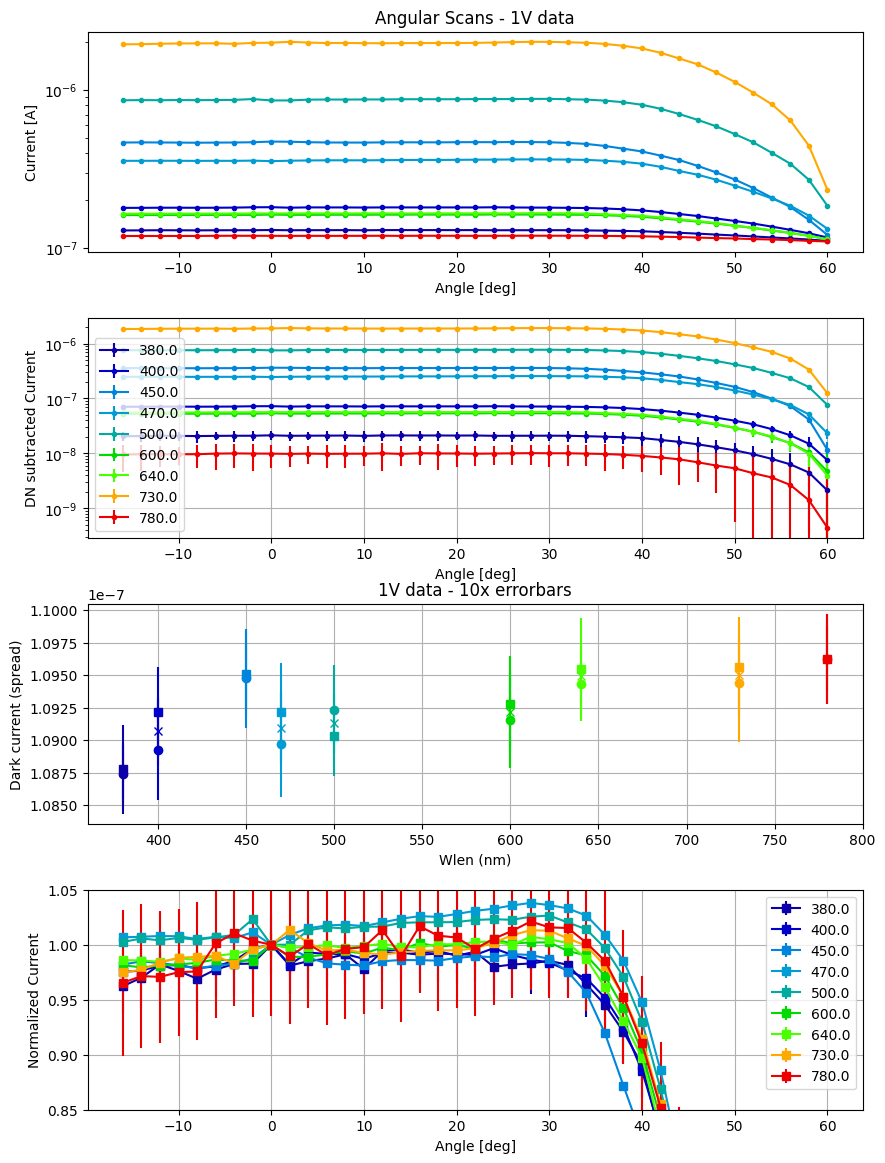

In [32]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, sharex=False, figsize = (10, 14))

# bad data list (has negative current with DN subtraction)
# MANUALLY EDITED THE LAST ENTRY TO HAVE THE SAME DN AS FIRST LINE
# badList = "veraData/HPK_angularScans_March2024/HPKW_angular_780nm_23C_0.5mm_slit_1oV.csv"

skip1V = ["830"]
vis1V = []
# 1V loop
for i, file in enumerate(sorted_f1V_list):
    # print(file)
    if any(word in file for word in skip1V):
        continue
    angData = AngularData(file)
    
    angData.LoadRawdata()
    ax1.errorbar(angData.xRaw, angData.Iraw, angData.IrawErr, marker = ".", color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"), label = angData.wlen)

    d1, ed1, d2, ed2 = angData.GetDark()
    angData.SubtractDark()
    ax2.errorbar(angData.xRaw, angData.Iraw, 10*angData.IrawErr, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"), label = angData.wlen)
    
    ax3.errorbar(angData.wlen, d1, ed1, marker = "s",color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"))
    ax3.errorbar(angData.wlen, d2, ed2, marker = "o",color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"))
    ax3.errorbar(angData.wlen, angData.darkAvg, angData.darkError, marker = "x",color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"))
    
    angData.Normalize()  
    ax4.errorbar(angData.xRaw, angData.Inorm, angData.InormErr, marker = "s",color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"), label = angData.wlen)
    
    vis1V.append(angData)

ax1.set_title("Angular Scans - 1V data")
ax1.set_ylabel("Current [A]")
ax1.set_xlabel("Angle [deg]")

ax1.set_yscale("log")

ax2.set_xlabel("Angle [deg]")
ax2.set_ylabel("DN subtracted Current")
ax2.legend()
ax2.grid()

# ax2.set_ylim(5e-8, 5e-7)
ax2.set_yscale("log")

ax3.set_xlabel("Wlen (nm)")
ax3.set_title("1V data - 10x errorbars")
ax3.set_ylabel("Dark current (spread)")
ax3.grid()

# ax3.set_yscale("log")

ax4.grid()
ax4.set_ylim(0.85, 1.05)
ax4.set_xlabel("Angle [deg]")
ax4.set_ylabel("Normalized Current")
ax4.legend()

plt.subplots_adjust(hspace=0.3)
plt.show()

---
## UV Data - Feb 2024 - many .csv's

This is cold!

['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/veraData/angular_scans_VUV_feb2024/HPKW_angular_210nm_-110C_0.5mm_slit_6oV.csv', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/veraData/angular_scans_VUV_feb2024/HPKW_angular_225nm_-110C_0.5mm_slit_6oV.csv', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/veraData/angular_scans_VUV_feb2024/HPKW_angular_235nm_-110C_0.5mm_slit_6oV.csv', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/veraData/angular_scans_VUV_feb2024/HPKW_angular_190nm_-110C_0.5mm_slit_6oV.csv']


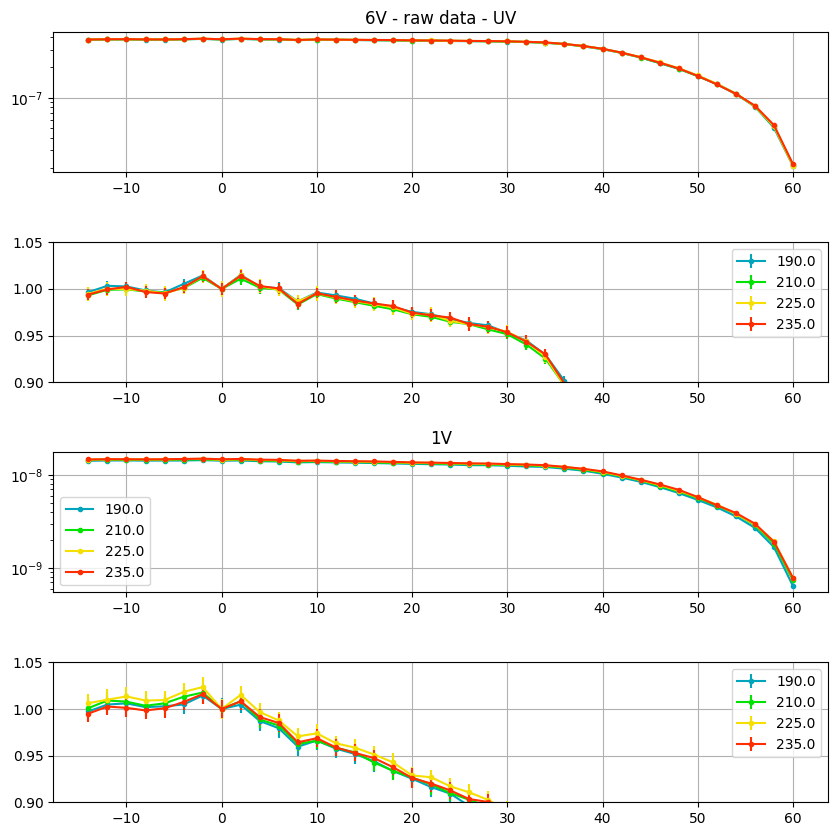

In [33]:
dataPath = os.path.join(VERA_DATA_PATH, "angular_scans_VUV_feb2024")

filelist_6V = get_csv_files_with_identifier(dataPath, "6oV")
print(filelist_6V)
sorted_f6V_list = sorted(filelist_6V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))
uv6V = []

filelist_1V = get_csv_files_with_identifier(dataPath, "1oV")
sorted_f1V_list = sorted(filelist_1V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))
uv1V = []

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize = (10, 10))

for i, file in enumerate(sorted_f6V_list):
    angData = AngularData(file)
    angData.LoadData(doDark = False, normalize=True)
    uv6V.append(angData)    
    
    ax1.semilogy(angData.xRaw, angData.Iraw, marker = ".", color= MS.map_value_to_hsv(angData.wlen, 160, 250, map="nipy_spectral"), label = angData.wlen)
    ax2.errorbar(angData.xRaw, angData.Inorm, angData.InormErr, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 160, 250, map="nipy_spectral"), label = angData.wlen)


for i, file in enumerate(sorted_f1V_list):
    angData = AngularData(file)
    angData.LoadData(doDark = False, normalize=True)
    uv1V.append(angData)
    
    ax3.semilogy(angData.xRaw, angData.Iraw, marker = ".", color= MS.map_value_to_hsv(angData.wlen, 160, 250, map="nipy_spectral"), label = angData.wlen)
    ax4.errorbar(angData.xRaw, angData.Inorm, angData.InormErr, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 160, 250, map="nipy_spectral"), label = angData.wlen)


ax1.set_title("6V - raw data - UV")
ax1.grid()

ax2.grid()
ax2.legend()
ax2.set_ylim(0.9, 1.05)

ax3.set_title("1V")
ax3.grid()
ax3.legend()

ax4.grid()
ax4.set_ylim(0.9, 1.05)
ax4.legend()

plt.subplots_adjust(hspace=0.5)
plt.show()

---
### Large Pinhole data - March 27th 2024
smaller pinhole (0.5mm)


In [34]:
import numpy as np
## New Data (June 2024)
print("---- New Data ----")

file_pathPinhole = os.path.join(VERA_DATA_PATH, "HPKW_1025_Angular_beammaps_T23C_0.5mm_pinhole_Mar_28_2024.csv")

df = pd.read_csv(file_pathPinhole, header=0)
# print(df.head())
# print(df.tail())

dfNames = df.columns
# print(dfNames.values)
[print(i, name) for i, name in enumerate(dfNames)]
# print(df.columns)

# data_anglesHR = df[strA].unique()
strA = dfNames[0]
strWlen = dfNames[1]
strV = dfNames[2]
strI = dfNames[3]
strIerr = dfNames[4]
strFwhm = dfNames[5]

# filtering crap data
df = df[df[strWlen] > 100]
df = df[df[strA].abs() <= 61]
df[strA] *= -1 

data_voltages = df[strV].unique()
data_wlensAll = df[strWlen].unique()
data_fwhm = df[strFwhm].unique()
data_wlensAll = np.sort(data_wlensAll)

# data ranges (after minor filtering)
print("-------- Data ranges after filtering out nonsense data --------")
print("angle range:", df[strA].min(), df[strA].max())

print("voltages:", data_voltages)
print("wavelengths:", data_wlensAll)

# print("wlen range:", df[strWlen].min(), df[strWlen].max())
print("fwhm range:", data_fwhm)

---- New Data ----
0 Angle (starting from -60deg) [deg]
1 Wavelength [nm]
2 Overvoltage [V]
3 Current [A]
4 Error[A]
5 Wavelength FWHM[nm]
-------- Data ranges after filtering out nonsense data --------
angle range: -13 60
voltages: [6]
wavelengths: [389.958 589.945 709.952]
fwhm range: [0 9]


False
False
38 38 38
False
False
38 38 38
False
False
38 38 38


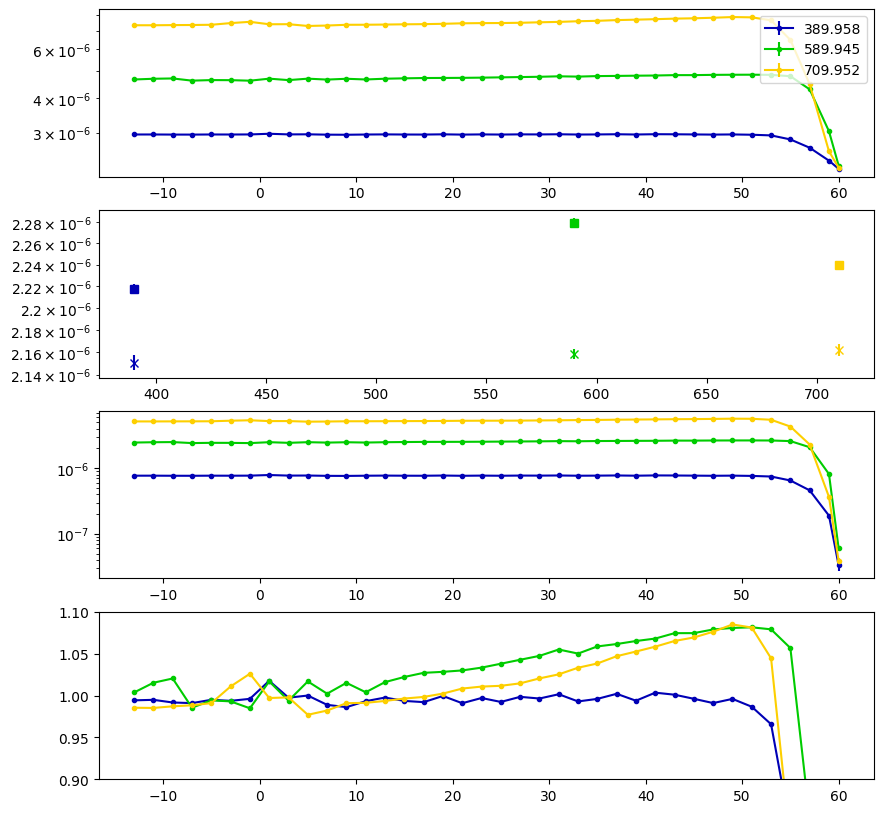

In [35]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize = (10, 10), height_ratios=[1, 1, 1, 1])

angleMean_range = 5
    
midMarchData = []
# only wlen, voltage here
for i, wlen in enumerate(data_wlensAll):
    
    # filtering
    dfWlen = df[(df[strWlen] == wlen)]
    
    # if dfWlen.empty:
    #     continue
    
    # angles = dfWlen[strA].values
    
    ao = BuildAngularObject_fromDF(dfWlen, strWlen, strFwhm, strV, strA, strI, strIerr, angleMean_range, [1, -1], False, False)
    ax1.errorbar(ao.angles, ao.yRaw, ao.yRawErr, marker = ".", color = MS.map_value_to_hsv(wlen, 300, 850, map="nipy_spectral"), label = wlen)

    ao.GetDark()
    ax2.errorbar(ao.wlen, ao.d1, ao.d1err, marker = "s", color = MS.map_value_to_hsv(wlen, 300, 850, map="nipy_spectral"))
    ax2.errorbar(ao.wlen, ao.d2, ao.d2err, marker = "x", color = MS.map_value_to_hsv(wlen, 300, 850, map="nipy_spectral"))
    
    ao.SubtractDark()
    ax3.errorbar(ao.angles, ao.yRaw, ao.yRawErr, marker = ".", color = MS.map_value_to_hsv(wlen, 300, 850, map="nipy_spectral"), label = wlen)

    print(np.any(ao.yRawErr < 0))
    ao.Normalize_fromSelfArrays(angleMean_range)
    
    print(np.any(ao.yNorm < 0))
    ax4.errorbar(ao.angles, ao.yNorm, 0, marker = ".", color = MS.map_value_to_hsv(wlen, 300, 850, map="nipy_spectral"), label = wlen)
    
    print(len(ao.angles), len(ao.yNorm), len(ao.yNormErr))
    
    midMarchData.append(ao)
# ax.legend(title=f"FWHM: {fwhm}nm")
# ax.grid()

ax1.legend()
ax1.set_yscale("log")

ax2.set_yscale("log")
ax3.set_yscale("log")

ax4.set_ylim(0.9, 1.1)
# ax4.set_ylim(0., 1.3)

# fig.suptitle(f"Raw Data - {newPickV} Vov")
plt.show()

---
## New data - UV and Vis - (June 2024)
This is cold!

- ignore the dark current, skip wlens < 100

- turn off DN in ao creation

In [37]:
import numpy as np
## New Data (June 2024)
print("---- New Data ----")

file_pathHR = os.path.join(VERA_DATA_PATH, "HPKW_1025_Angular_beammaps_T-110C_June2024.csv")

df = pd.read_csv(file_pathHR, header=0)
# print(df.head())
# print(df.tail())

dfNames = df.columns
# print(dfNames.values)
[print(i, name) for i, name in enumerate(dfNames)]
# print(df.columns)

# data_anglesHR = df[strA].unique()
strA = dfNames[0]
strWlen = dfNames[1]
strV = dfNames[2]
strI = dfNames[3]
strIerr = dfNames[4]
strFwhm = dfNames[5]

# filtering crap data
df = df[df[strWlen] > 100]
df = df[df[strA].abs() <= 61]
df[strA] *= -1

data_voltages = df[strV].unique()
data_wlensAll = df[strWlen].unique()
data_fwhm = df[strFwhm].unique()
data_wlensAll = np.sort(data_wlensAll)

# data ranges (after minor filtering)
print("-------- Data ranges after filtering out nonsense data --------")
print("angle range:", df[strA].min(), df[strA].max())

print("voltages:", data_voltages)
print("wavelengths:", data_wlensAll)

print("wlen range:", df[strWlen].min(), df[strWlen].max())
print("fwhm range:", data_fwhm)



---- New Data ----
0 Angle (starting from -60deg) [deg]
1 Wavelength [nm]
2 Overvoltage [V]
3 Current [A]
4 Error[A]
5 Wavelength FWHM[nm]
-------- Data ranges after filtering out nonsense data --------
angle range: -13 60
voltages: [2 6]
wavelengths: [160.009 189.963 209.935 209.964 224.884 234.977 349.941 379.943 379.972
 399.946 399.975 449.924 469.931 469.96  499.961 499.99  599.952 599.981
 639.887 659.898 659.927 729.967 729.997 779.872 829.983]
wlen range: 160.009 829.983
fwhm range: [9.  5.  1.5]


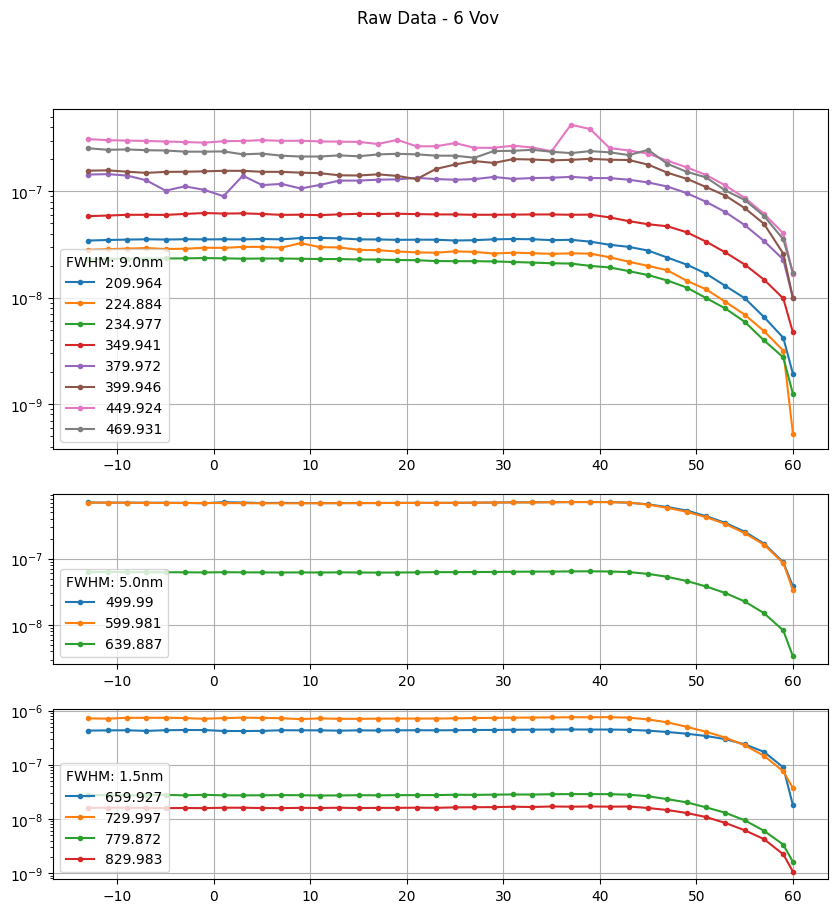

In [38]:
fig, axes = plt.subplots(3, 1, figsize = (10, 10), height_ratios=[2, 1, 1])

newPickV = data_voltages[1]
pickFWHM = data_fwhm[-1]
angleMean_range = 5
    
for i, fwhm in enumerate(data_fwhm):
    ax = axes[i]
    for wlen in data_wlensAll:
        
        # filtering
        dfWlen = df[(df[strWlen] == wlen) & (df[strV] == newPickV) & (df[strFwhm] == fwhm)]
        
        if dfWlen.empty:
            continue
        
        angles = dfWlen[strA].values
        
        xVals = angles
        yRaw = dfWlen[strI].values
        yRaw_err = dfWlen[strIerr].values
        
        ax.semilogy(xVals, yRaw, marker = ".", label = wlen)
    
    ax.legend(title=f"FWHM: {fwhm}nm")
    ax.grid()

ax1.set_ylim(0.9, 1.1)
ax1.legend()
fig.suptitle(f"Raw Data - {newPickV} Vov")
plt.show()

---
### New data - normalized

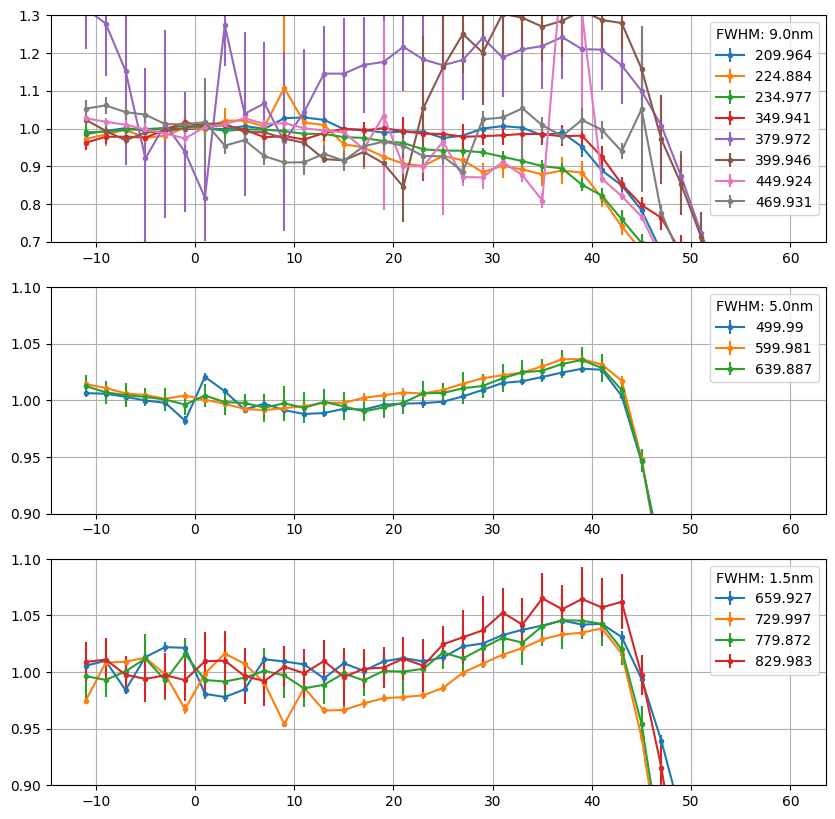

In [39]:
fig, axes = plt.subplots(3, 1, figsize = (10, 10))

newPickV = data_voltages[1]
angleMean_range = 5

data3_6v = []
    
offVsWlen = []
for i, fwhm in enumerate(data_fwhm):
    ax = axes[i]
    for wlen in data_wlensAll:
        
        # filtering
        dfWlen = df[(df[strWlen] == wlen) & (df[strV] == newPickV) & (df[strFwhm] == fwhm)]
        
        if dfWlen.empty:
            continue
        
        aobj = BuildAngularObject_fromDF(dfWlen, strWlen, strFwhm, strV, strA, strI, strIerr, angleMean_range, doDark=False, darkInd=[0, -1], normalize=True)
        
        data3_6v.append(aobj)
        
        ax.errorbar(aobj.angles, aobj.yNorm, aobj.yNormErr, marker = ".", label = wlen)
    
    ax.legend(title=f"FWHM: {fwhm}nm")
    ax.grid()

axes[0].set_ylim(0.7, 1.3)
axes[1].set_ylim(0.9, 1.1)
axes[2].set_ylim(0.9, 1.1)
plt.show()

---
# Organizing (and converting) all datasets

In [40]:
# list all the data sets I have
l = [uv6V, uv1V, vis6V, vis1V]
[len(ll) for ll in l]

data1_6V = [] # 6V UV
for oldData in uv6V:
    aobj = BuildAngularObject_fromAngularData(oldData, fwhm = None, angleMean_range = 5)
    data1_6V.append(aobj)
    
data2_6V = [] # 6V vis - warm
for oldData in vis6V:
    aobj = BuildAngularObject_fromAngularData(oldData, fwhm = None, angleMean_range = 5)
    data2_6V.append(aobj)

print(len(vis6V))
print(len(data2_6V))
data3_6v; # 6V full spectrum - cold

data4_6V = midMarchData # 6V, partial spectrum, warm, smaller pinhole

9
9


In [41]:
## Starting real analysis. Some variables we care abou
tOxide = 17.5 # nm

degShoulder = 25
stdCut = 0.06

pnArgs = {"FF":0.6, "tOxide":tOxide, "dp_star":1.5, "Xpn":1.2e3, "dw_star":5e3, "pe":0.95, "ph":0.35, "window":True, "smoothSigma":None}

pdeAtWlen = PDE_allArgs(wlen = 420, theta1=0, **pnArgs)


-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


STD values: [0.012521066913415738, 0.012552489617464748, 0.012470427576610623, 0.012113701160545552, 0.012237594364500693, 0.004309342104860285, 0.0052584556090771025, 0.007003348205844714, 0.005684669973006712, 0.009005107903297263, 0.00833405330875166, 0.006306777321540212, 0.018507795833803353, 0.013323815140661431, 0.047202119431855365, 0.018372163119441478, 0.013630834597158022, 0.13046781295909682, 0.06367646929211154, 0.03757447359673008, 0.05050025939260787, 0.008504431234937111, 0.006297585693770941, 0.005716679986055358, 0.012871401638910844, 0.017891228231371067, 0.00836278586867999, 0.00815829857063471]


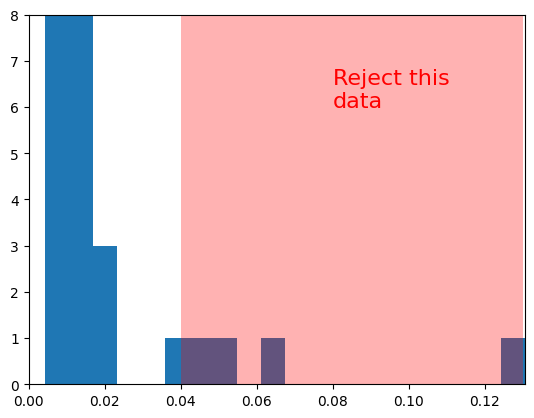

In [42]:
c1 = 'green'
c2 = 'blue'
c3 = 'red'


for dat in data1_6V + data2_6V + data3_6v + data4_6V:
    # print(dat.wlen, dat.fwhm)
    
    dat.DataQuality()
    dat.FactorOutTransmission(tOxide)
    
stdVals = [dat.GetNormalizedSTD(degShoulder) for dat in data1_6V + data2_6V + data3_6v]
print("STD values:", stdVals)

# stdVals_longer = [dat.GetNormalizedSTD(40) for dat in data1_6V + data2_6V + data3_6v]

plt.hist(stdVals, bins = 20)
plt.fill_betweenx([0, 8], 0.04, 0.13, color = "red", edgecolor=None, alpha = 0.3)
plt.ylim(0, 8)
plt.xlim(0, max(stdVals))

plt.text(0.08, 6, "Reject this \ndata", fontsize = 16, color = "red")
plt.show()

9
bad std at wlen: 264.884
bad std at wlen: 419.972
bad std at wlen: 429.946
bad std at wlen: 519.931


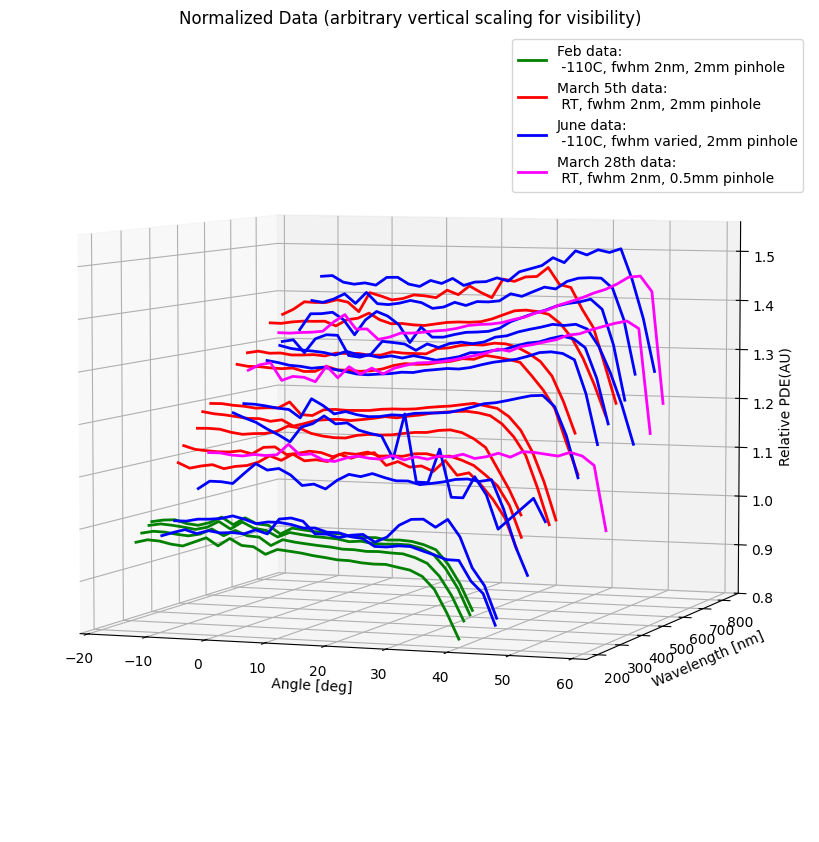

In [43]:
from FillBetween3d import *
from matplotlib.lines import Line2D

# 3d plot
fig = plt.figure(figsize = (12, 10))

axNorm = fig.add_subplot(111, projection='3d')
fig.subplots_adjust(left=0.1, right=1.0, bottom=0.1, top=0.9)

c1 = 'green'
c2 = 'red'
c3 = 'blue'
c4 = 'magenta'

# scaling wlens
signalLim = (0.8, 1.2)
wlenScale = 0.001
scaleByWlen = lambda wlen: 0.7*(wlen - 220)*wlenScale

# wavelengths
allWlens = [dat.wlen for dat in data1_6V + data2_6V + data3_6v]
wlenBuffer = 1.1
print(len(data2_6V))
counter = 0
for col, dlist in [(c1, data1_6V), (c2, data2_6V), (c3, data3_6v), (c4, data4_6V)]:
    for dat in dlist:
        xVals = dat.angles
        refVals = dat.yNorm_noOptics
        
        # print("on wlen", dat.wlen)
        
        wlenUse = dat.wlen
        
        while 1: # spacing out slightly for visualization
            minDifference = min(np.abs(wlenUse - np.array(allWlens)))
            if minDifference > wlenBuffer:
                break
            wlenUse += 10
        
        allWlens.append(wlenUse)
        # print("final wlenUse", wlenUse)
        
        # remove data that is outside signal limits for visualization
        limitMap = (refVals > signalLim[0]) & (refVals < signalLim[1])
        xVals = xVals[limitMap]
        refVals = refVals[limitMap]
        
        # skip bad data
        if dat.GetNormalizedSTD(degShoulder) > 0.04:
            print("bad std at wlen:", wlenUse)
            continue
        
        # ySmoothed = gaussian_filter1d(refVals, 2)
        fData = interp1d(xVals, refVals, kind = "cubic")
        zPlot = fData(xVals) + scaleByWlen(dat.wlen)
        yWlens = np.full_like(xVals, wlenUse)
        
        setBottom = [xVals, yWlens, np.ones_like(xVals)*signalLim[0]]
        setTop = [xVals, yWlens, zPlot]

        axNorm.plot(*setTop, lw=2, zorder=20, c=col)
        fill_between_3d(axNorm, *setBottom, *setTop, mode = 1, c=col, alpha = 0.)
        counter += 1
     

# plane at x = 30 
yPlane = np.linspace(min(allWlens), max(allWlens), 100)
xPlane = np.full_like(yPlane, degShoulder)
zPlane_low = np.full_like(yPlane, signalLim[0])
zPlane_high = np.full_like(yPlane, signalLim[1])
setLow = [xPlane, yPlane, zPlane_low]
setHigh = [xPlane, yPlane, zPlane_high]
# fill_between_3d(axNorm, *setLow, *setHigh, mode = 1, c='black', alpha = 0.6)

setBottom = []
  
axNorm.set_title("Normalized Data (arbitrary vertical scaling for visibility)")
axNorm.grid()
axNorm.set_zlim(signalLim[0], 1.3*signalLim[1])
# Correct the z limit of the plot.
# axNorm.set_zlim((0,np.max([f1,f2,f3])))
axNorm.view_init(elev=5, azim=-70)


# Create the legend
line1 = Line2D([0], [0], color=c1, lw=2)
line2 = Line2D([0], [0], color=c2, lw=2)
line3 = Line2D([0], [0], color=c3, lw=2)
line4 = Line2D([0], [0], color=c4, lw=2)
legText = [
    'Feb data:\n -110C, fwhm 2nm, 2mm pinhole',
    'March 5th data:\n RT, fwhm 2nm, 2mm pinhole',
    'June data:\n -110C, fwhm varied, 2mm pinhole',
    'March 28th data:\n RT, fwhm 2nm, 0.5mm pinhole']
axNorm.legend([line1, line2, line3, line4], legText)

axNorm.set_xlabel("Angle [deg]")
axNorm.set_ylabel("Wavelength [nm]")
axNorm.set_zlabel("Relative PDE(AU)", labelpad=2)

plt.show()

---
### back to proper code

bad std at wlen: 224.884
bad std at wlen: 379.972
bad std at wlen: 399.946
high data at wlen: 449.924
bad std at wlen: 469.931


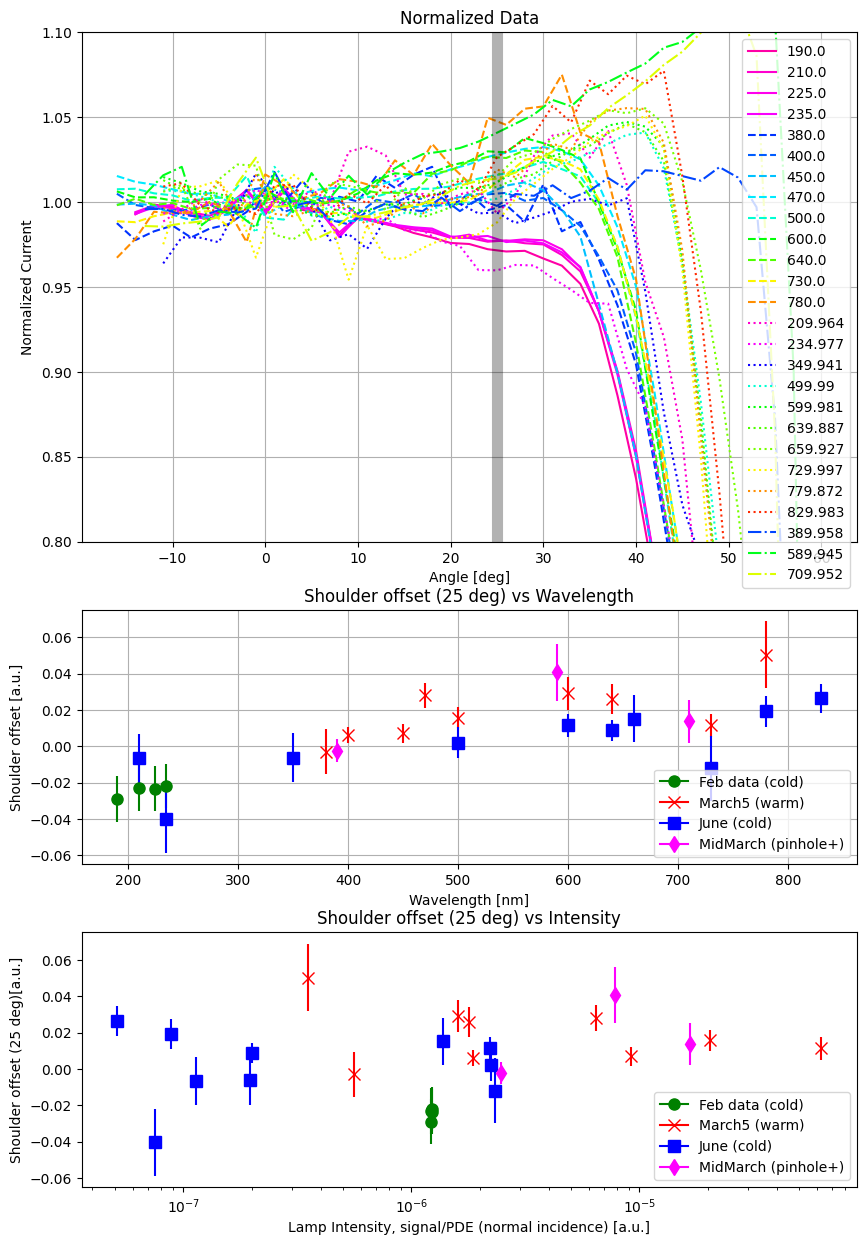

In [44]:
# 3d plot
fig, axes = plt.subplots(3, 1, figsize = (10, 15), height_ratios=[2, 1, 1])
axNorm, axWlen, axIntensity = axes

l1 = '-'
l2 = '--'
l3 = ':'
l4 = '-.'

c1 = 'green'
c2 = 'red'
c3 = 'blue'
c4 = 'magenta'

shouldVswlen_y = []
shouldVswlen_x = []
for col, dlist in [(c1, data1_6V), (c2, data2_6V), (c3, data3_6v), (c4, data4_6V)]:
    if col == c1:
        mark= "o"
        line = l1
    elif col == c2:
        mark= "x"
        line = l2
    elif col == c3:
        mark= "s"
        line = l3
    elif col == c4:
        mark= "d"
        line = l4
        
    for dat in dlist:
        xVals = dat.angles
        yVals = dat.yNorm_noOptics
        
        restrictedSTD = dat.GetNormalizedSTD(degShoulder)
        if restrictedSTD > 0.04:
            print("bad std at wlen:", dat.wlen)
            continue
        
        if max(yVals) > 1.2:
            print("high data at wlen:", dat.wlen)
            # print("from array:",
            continue

        # histogram STD values
        col_hsv = MS.map_value_to_hsv(dat.wlen, 120, 850, map = "hsv_r")
        
        # ySmoothed = gaussian_filter1d(yVals, 2)
        fData = interp1d(xVals, yVals, kind = "cubic")

        axNorm.plot(xVals, yVals, color = col_hsv, linestyle = line, label = dat.wlen)
        # axNorm.fill_between(xVals, yVals - restrictedSTD, yVals + restrictedSTD, color = col, alpha = 0.1)

        # shoulder stuff
        offAtDeg = fData(degShoulder) - 1.
        
        # building the data for the vs wlen plot
        shouldVswlen_y.append(offAtDeg)
        shouldVswlen_x.append(dat.wlen)
        
        # vs wlen
        axWlen.errorbar(dat.wlen, offAtDeg, restrictedSTD, marker= mark, markersize=8, color = col, linestyle = line)
        
        # vs intensity
        axIntensity.errorbar(dat.yNormalMean/pdeAtWlen, offAtDeg, restrictedSTD, marker= mark, markersize=8, color = col, linestyle = line)
    
axIntensity.set_xscale("log")
# axIntensity.set_yscale("log")

axNorm.vlines(degShoulder, 0.8, 1.2, color = "black", linewidth=8, alpha=0.3, linestyle = "-")

axNorm.legend()
axNorm.set_title("Normalized Data")

axNorm.set_ylim(0.8, 1.1)
axNorm.grid()

axNorm.set_xlabel("Angle [deg]")
axNorm.set_ylabel("Normalized Current")


axWlen.set_title(f"Shoulder offset ({degShoulder} deg) vs Wavelength")
axWlen.set_xlabel("Wavelength [nm]")
axWlen.set_ylabel("Shoulder offset [a.u.]")
axWlen.grid()

# Create the markers
marker1 = Line2D([0], [0], marker='o', color=c1, markerfacecolor=c1, markersize=8)
marker2 = Line2D([0], [0], marker='x', color=c2, markerfacecolor=c2, markersize=8)
marker3 = Line2D([0], [0], marker='s', color=c3, markerfacecolor=c3, markersize=8)
marker4 = Line2D([0], [0], marker='d', color=c4, markerfacecolor=c4, markersize=8)

# Create the legend
legMarkers = [marker1, marker2, marker3, marker4]
legText = ['Feb data (cold)', 'March5 (warm)', 'June (cold)', 'MidMarch (pinhole+)']
axWlen.legend(legMarkers, legText, loc = "lower right")

axIntensity.set_title(f"Shoulder offset ({degShoulder} deg) vs Intensity")
axIntensity.set_xlabel("Lamp Intensity, signal/PDE (normal incidence) [a.u.]")
axIntensity.set_ylabel(f"Shoulder offset ({degShoulder} deg)[a.u.]")
axIntensity.legend(legMarkers, legText, loc = "lower right")

plt.show()

---
### Fitting the UV data with the shadowing function

In [45]:
# doing fit
from iminuit.cost import LeastSquares

UV_FFdatatoFit_x = []
UV_FFdatatoFit_y = []
UV_FFdatatoFit_yerr = []

shoulderCutoff = 25

for i, angData in enumerate(data1_6V):
    col = MS.map_value_to_hsv(wlen, 100, 400, map="nipy_spectral")

    wlen = angData.wlen
    
    filter = (angData.angles < shoulderCutoff)
    UV_FFdatatoFit_x.extend(angData.angles[filter])
    UV_FFdatatoFit_y.extend(angData.yNorm_noOptics[filter])
    UV_FFdatatoFit_yerr.extend(angData.yNormErr_noOptics[filter])

UV_FFdatatoFit_x = np.array(UV_FFdatatoFit_x)
least_squares_fit1 = LeastSquares(UV_FFdatatoFit_x, UV_FFdatatoFit_y, UV_FFdatatoFit_yerr, FF_theta_relative)
mUV_fit1 = Minuit(least_squares_fit1, W=0.0, H=0.01, offset = 0.015)
mUV_fit1.fixed["W"] = True

mUV_fit1.migrad()
mUV_fit1.hesse()
# print(mUV_fit1)


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 128.7 (χ²/ndof = 1.7)      │              Nfcn = 44               │
│ EDM = 6.53e-18 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ W      │    0.0    │    0.1    │            │            │         │         │  yes  │
│ 1 │ H      │   0.055   │   0.004   │            │            │         │         │       │
│ 2 │ offset │  0.7e-3   │  0.9e-3   │            │            │         │         │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────────┬────────────────────────────┐
│        │        W        H   offset │
├────────┼────────────────────────────┤
│      W │        0        0        0 │
│      H │        0 1.61e-05   3.0e-6 │
│ offset │        0   3.0e-6  7.9e-07 │
└────────┴────────────────────────────┘

Fitted height: 2.73 +/- 0.20 um


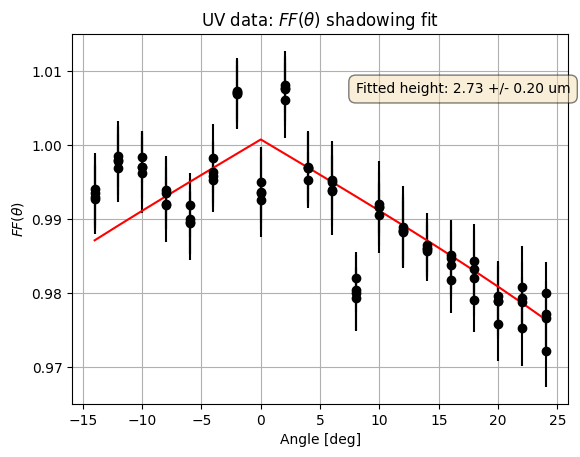

In [46]:
UV_FFdatatoFit_x_plot = np.sort(UV_FFdatatoFit_x)

print(f'Fitted height: {mUV_fit1.values["H"] * pp:0.2f} +/- {mUV_fit1.errors["H"] * pp:0.2f} um')

plt.errorbar(UV_FFdatatoFit_x, UV_FFdatatoFit_y, UV_FFdatatoFit_yerr, linestyle = "None", marker = "o", color = "black", label = "data")
# UV_FFdatatoFit_x = np.sort(UV_FFdatatoFit_x)
plt.plot(UV_FFdatatoFit_x_plot, FF_theta_relative(theta=UV_FFdatatoFit_x_plot, W=mUV_fit1.values["W"], H=mUV_fit1.values["H"], offset=mUV_fit1.values["offset"]), color = "red", label = "fit")

ax = plt.gca()
ax.grid()

ax.set_title(r"UV data: $FF(\theta)$ shadowing fit")
ax.set_xlabel(r"Angle [deg]")
ax.set_ylabel(r"$FF(\theta)$")

tbox = dict(boxstyle='round', facecolor='wheat', alpha=0.5, pad = 0.5)
ax.text(8, 1.007, f'Fitted height: {mUV_fit1.values["H"] * pp:0.2f} +/- {mUV_fit1.errors["H"] * pp:0.2f} um',
        bbox=tbox)

plt.show()


In [47]:
print("best fit normal incidence FF: ", FF_theta_relative(theta=0, W=W50, H=mUV_fit1.values["H"], offset=mUV_fit1.values["offset"]))
mUV_fit1.covariance.correlation()

best fit normal incidence FF:  0.6007376883287106


,W,H,offset
W,0,0,0
H,0,1,0.8
offset,0,0.8,1
